# Lab 1 적용 — 데이터 로딩과 기술통계 (Give Me Some Credit)

**이번 단계의 질문:** 이 데이터는 어떻게 생겼고, 모델링 전에 무엇을 조심해야 하나?

Lab 1의 순서를 그대로 따른다: CSV 불러오기 3가지 → 미리보기 → 크기 → 자료형 → 기술통계 → 클래스 분포 → 상관관계 → 왜도.

In [1]:
# 공통 설정: 열 이름은 Lab처럼 짧은 이름을 붙인다
from pandas import read_csv, set_option
import numpy

filename = '../data/givemesomecredit.csv'
names = ['target', 'revol', 'age', 'late30', 'debt', 'income', 'depend', 'defaulted', 'loans']
set_option('display.width', 120)
set_option('display.precision', 3)   # Lab 원본의 set_option('precision', 3)은 최신 pandas에서 오류

| 짧은 이름 | 원래 열 이름 | 의미 (NOTE 논문 Table 1) |
|---|---|---|
| target | SeriousDlqin2yrs | 2년 내 90일 이상 연체 여부 (정답, 0/1) |
| revol | RevolvingUtilizationOfUnsecuredLines | 신용카드·신용한도 대비 사용 비율 |
| age | age | 나이 |
| late30 | NumberOfTime30-59DaysPastDueNotWorse | 최근 2년간 30–59일 연체 횟수 |
| debt | DebtRatio | 월 부채 상환액 ÷ 월 소득 |
| income | MonthlyIncome | 월 소득 |
| depend | NumberOfDependents | 부양가족 수 |
| defaulted | CombinedDefaulted | 60일 이상 연체 이력 통합 (0/1) |
| loans | CombinedCreditLoans | 대출·신용한도 보유 통합 (0/1) |

## 1. CSV 불러오기 3가지 방법

Lab 1은 "헤더가 없는 파일"을 가정한다. **이 파일은 첫 줄이 열 이름(헤더)**이라 그대로 따라 하면 첫 줄이 데이터로 섞인다.
그래서 세 방법 모두 헤더를 건너뛰도록 고쳤다.

In [2]:
# (1) Python 표준 라이브러리 csv
import csv
raw_data = open(filename, 'rt')
reader = csv.reader(raw_data, delimiter=',', quoting=csv.QUOTE_NONE)
next(reader)                      # 헤더 한 줄 건너뛰기
x = list(reader)
data = numpy.array(x).astype('float')
raw_data.close()
print('csv     :', data.shape)

# (2) NumPy loadtxt
from numpy import loadtxt
data = loadtxt(filename, delimiter=',', skiprows=1)   # skiprows=1로 헤더 제외
print('numpy   :', data.shape)

# (3) Pandas read_csv  ← 이후 단계에서 계속 사용
data = read_csv(filename, names=names, header=0)       # header=0: 첫 줄을 헤더로 보고 이름은 names로 교체
print('pandas  :', data.shape)

csv     : (150000, 9)
numpy   : (150000, 9)
pandas  : (150000, 9)


## 2. 데이터 미리보기 (head)

In [3]:
print(data.head(20))

    target  revol  age  late30      debt  income  depend  defaulted  loans
0        1  0.766   45       2     0.803    9120       2          1      1
1        0  0.957   40       0     0.122    2600       1          0      0
2        0  0.658   38       1     0.085    3042       0          1      0
3        0  0.234   30       0     0.036    3300       0          0      0
4        0  0.907   49       1     0.025   63588       0          1      1
5        0  0.213   74       0     0.376    3500       1          0      0
6        0  0.306   57       0  5710.000    6638       0          0      1
7        0  0.754   39       0     0.210    3500       0          0      1
8        0  0.117   27       0    46.000    6638       0          0      0
9        0  0.189   57       0     0.606   23684       2          0      1
10       0  0.644   30       0     0.309    2500       0          0      0
11       0  0.019   51       0     0.532    6501       2          0      1
12       0  0.010   46   

## 3. 데이터 크기 (shape)

In [4]:
print(data.shape)

(150000, 9)


## 4. 속성별 자료형 (dtypes)

In [5]:
print(data.dtypes)

target         int64
revol        float64
age            int64
late30         int64
debt         float64
income         int64
depend         int64
defaulted      int64
loans          int64
dtype: object


## 5. 기술통계 (describe)

In [6]:
print(data.describe().T)

              count      mean        std   min       25%       50%       75%        max
target     150000.0     0.067      0.250   0.0     0.000     0.000     0.000  1.000e+00
revol      150000.0     6.048    249.755   0.0     0.030     0.154     0.559  5.071e+04
age        150000.0    52.296     14.771  21.0    41.000    52.000    63.000  1.090e+02
late30     150000.0     0.421      4.193   0.0     0.000     0.000     0.000  9.800e+01
debt       150000.0   353.005   2037.819   0.0     0.175     0.367     0.868  3.297e+05
income     150000.0  6673.266  12880.469   0.0  3903.000  6600.000  7400.000  3.009e+06
depend     150000.0     0.737      1.107   0.0     0.000     0.000     1.000  2.000e+01
defaulted  150000.0     0.202      0.402   0.0     0.000     0.000     0.000  1.000e+00
loans      150000.0     0.743      0.437   0.0     0.000     1.000     1.000  1.000e+00


## 6. 클래스 분포

Lab 1: *"분류 문제에서는 클래스가 얼마나 균형 잡혀 있는지 알아야 한다."*

In [7]:
class_counts = data.groupby('target').size()
print(class_counts)
ratio = class_counts / len(data) * 100
print('\n비율(%):'); print(ratio.round(2))
print('\n불균형 비율 (정상:연체) = 1 : %.2f' % (class_counts[0] / class_counts[1]))
print('모두 "정상"으로 예측할 때의 정확도(기준선) = %.2f%%' % ratio[0])

target
0    139974
1     10026
dtype: int64

비율(%):
target
0    93.32
1     6.68
dtype: float64

불균형 비율 (정상:연체) = 1 : 13.96
모두 "정상"으로 예측할 때의 정확도(기준선) = 93.32%


## 7. 속성 간 상관관계 (Pearson)

In [8]:
correlations = data.corr(method='pearson')
print(correlations)

           target      revol    age  late30   debt  income  depend  defaulted      loans
target      1.000 -1.802e-03 -0.115   0.126 -0.008  -0.018   0.047      0.314 -5.478e-02
revol      -0.002  1.000e+00 -0.006  -0.001  0.004   0.007   0.001     -0.002 -6.846e-04
age        -0.115 -5.899e-03  1.000  -0.063  0.024   0.034  -0.216     -0.127  1.068e-01
late30      0.126 -1.314e-03 -0.063   1.000 -0.007  -0.008  -0.005      0.199 -6.161e-02
debt       -0.008  3.961e-03  0.024  -0.007  1.000  -0.005  -0.044     -0.005  5.682e-02
income     -0.018  6.561e-03  0.034  -0.008 -0.005   1.000   0.058     -0.011  6.818e-02
depend      0.047  1.193e-03 -0.216  -0.005 -0.044   0.058   1.000      0.072  1.079e-01
defaulted   0.314 -1.697e-03 -0.127   0.199 -0.005  -0.011   0.072      1.000 -2.229e-02
loans      -0.055 -6.846e-04  0.107  -0.062  0.057   0.068   0.108     -0.022  1.000e+00


## 8. 왜도 (skew)

In [9]:
skew = data.skew()
print(skew.round(2))

target         3.47
revol         97.63
age            0.19
late30        22.60
debt          95.16
income       127.36
depend         1.63
defaulted      1.48
loans         -1.11
dtype: float64


## 9. 추가 확인 — 기술통계에서 이상해 보인 부분 파고들기

describe와 skew에서 눈에 띈 점을 숫자로 확인한다.

In [10]:
print('결측치 수            :', data.isnull().sum().sum())
print('완전히 같은 중복 행  :', data.duplicated().sum())
print()
print('revol(사용 비율) > 1     :', (data.revol > 1).sum(), '행 / 최댓값', data.revol.max())
print('debt(부채 비율) > 1      :', (data.debt > 1).sum(), '행 / 최댓값', data.debt.max())
print('late30 = 96 또는 98      :', data.late30.isin([96, 98]).sum(), '행 (연체 횟수로 불가능한 값 → 특수 코드)')
print('income = 0               :', (data.income == 0).sum(), '행')

결측치 수            : 0
완전히 같은 중복 행  : 1222

revol(사용 비율) > 1     : 3321 행 / 최댓값 50708.0
debt(부채 비율) > 1      : 35137 행 / 최댓값 329664.0
late30 = 96 또는 98      : 269 행 (연체 횟수로 불가능한 값 → 특수 코드)
income = 0               : 1634 행


In [11]:
# 월 소득에 유난히 자주 나오는 값 → 원래 빈 값을 채운 흔적
print(data.income.value_counts().head(5))
filled = data.income.isin([6638, 6746])
print('\n6638 또는 6746인 행:', filled.sum())
print('그중 debt > 1인 행   :', (filled & (data.debt > 1)).sum())
print('→ 소득이 비어 있던 고객은 debt 열에 "비율"이 아니라 부채 "금액"이 들어 있는 것으로 보인다.')

income
6638    16634
6746    13103
5000     2757
4000     2106
6000     1934
Name: count, dtype: int64

6638 또는 6746인 행: 29737
그중 debt > 1인 행   : 27904
→ 소득이 비어 있던 고객은 debt 열에 "비율"이 아니라 부채 "금액"이 들어 있는 것으로 보인다.


In [12]:
# 일반 상관계수(Pearson) vs 순위 상관계수(Spearman): 극단값의 영향 확인
compare = numpy.round(
    data.corr(method='pearson')['target'].to_frame('pearson')
        .join(data.corr(method='spearman')['target'].to_frame('spearman')), 3)
print(compare.drop('target'))

           pearson  spearman
revol       -0.002     0.240
age         -0.115    -0.117
late30       0.126     0.257
debt        -0.008     0.021
income      -0.018    -0.069
depend       0.047     0.047
defaulted    0.314     0.314
loans       -0.055    -0.055


## 10. 그림 저장 (장표용)

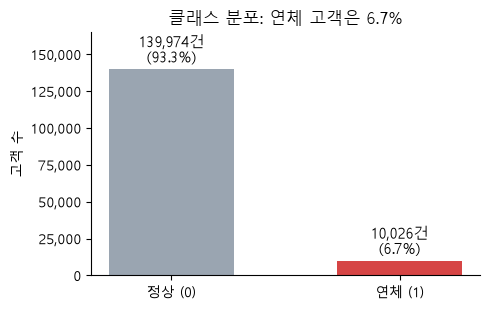

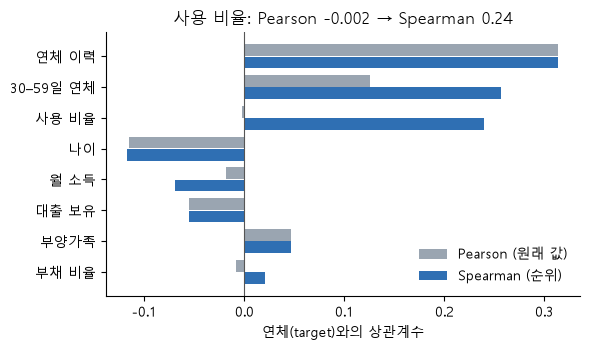

In [13]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# (1) 클래스 분포
fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar(['정상 (0)', '연체 (1)'], class_counts.values, color=['#9aa5b1', '#d64545'], width=0.55)
for b, n, r in zip(bars, class_counts.values, ratio.values):
    ax.text(b.get_x() + b.get_width() / 2, n + 2500, f'{n:,}건\n({r:.1f}%)', ha='center', va='bottom', fontsize=11)
ax.set_ylim(0, 165000); ax.set_ylabel('고객 수')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
ax.set_title('클래스 분포: 연체 고객은 6.7%', fontsize=12)
fig.tight_layout(); fig.savefig('../figures/lab1_class_balance.png', dpi=200); plt.show()

# (2) Pearson vs Spearman
c = compare.drop('target').rename(index={'revol': '사용 비율', 'age': '나이', 'late30': '30–59일 연체', 'debt': '부채 비율',
                                          'income': '월 소득', 'depend': '부양가족', 'defaulted': '연체 이력', 'loans': '대출 보유'})
c = c.reindex(c['spearman'].abs().sort_values().index)
fig, ax = plt.subplots(figsize=(6, 3.6))
y = numpy.arange(len(c))
ax.barh(y + 0.2, c['pearson'], height=0.38, color='#9aa5b1', label='Pearson (원래 값)')
ax.barh(y - 0.2, c['spearman'], height=0.38, color='#2f6fb3', label='Spearman (순위)')
ax.set_yticks(y); ax.set_yticklabels(c.index); ax.axvline(0, color='#555', lw=0.8)
ax.set_xlabel('연체(target)와의 상관계수'); ax.legend(frameon=False, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
ax.set_title('사용 비율: Pearson -0.002 → Spearman 0.24', fontsize=12)
fig.tight_layout(); fig.savefig('../figures/lab1_pearson_vs_spearman.png', dpi=200); plt.show()

## Verify your understanding (Lab 1 질문을 이 데이터에 적용)

**(a) 인스턴스와 변수 수는?** 150,000행, 9열 (입력 8개 + 정답 1개).

**(b) 변수가 모두 숫자인가?** 그렇다. 9개 열 모두 int64/float64라 바로 모델에 넣을 수 있다. 결측치도 0개 (전처리 완료 데이터).

**(c) 데이터가 균형 잡혀 있나?** 아니다. 연체 10,026건(6.68%) vs 정상 139,974건, 불균형 비율 1:13.96.
모두 "정상"이라고 찍어도 정확도 93.3%가 나온다 → **정확도로는 모델을 평가할 수 없다** (Lab 4에서 다룸).

**(d) 이상한 분포를 가진 변수가 있나?** 있다.
- 사용 비율(revol): 비율인데 최댓값 50,708, 1을 넘는 행 3,321개. 왜도 97.6
- 부채 비율(debt): 1을 넘는 행 35,137개. 그중 27,904행은 월 소득이 6638 또는 6746으로 채워진 행 → 소득이 비어 있던 고객은 비율 대신 부채 금액이 들어간 것으로 보인다
- 30–59일 연체(late30): 96, 98이라는 불가능한 값 269행 (특수 코드)
- 월 소득(income): 왜도 127.4. 6638(16,634행), 6746(13,103행)이 비정상적으로 많음 → 결측치를 채운 값

**(e) 어떻게 바로잡아야 하나?** Lab 2에서 다룬다. 치우친 변수에 로그 변환, 상한 자르기(clipping), 표준화 등을 시도하고
변환 전후 성능을 비교한다. 특수 코드(96/98)는 별도로 처리한다.

**(f) 비슷한 정보를 가진 변수가 있나?** 입력 변수끼리 상관계수는 최대 0.22(나이–부양가족)로 높은 쌍이 없다.
→ 다중공선성 걱정은 적다. 정답과는 **연체 이력(defaulted) 0.31**이 가장 강하다.

## 정리: 발견 → 다음 질문

- 발견 1: 연체 6.7%의 **극단적 불균형** → 정확도 93%는 의미가 없다
- 발견 2: **이상치와 채워 넣은 값**이 많아 분포가 심하게 치우쳐 있다
- 발견 3: 사용 비율은 Pearson으로는 무관(−0.002)해 보이지만 순위로 보면 0.24 → **극단값이 관계를 가리고 있다**

**다음 질문 (Lab 2):** 이 값들을 그대로 써도 되나? 어떻게 바꿔야 관계가 드러날까?